# Group G+H Multiple Regression

In [2]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import os

# --- Paths ---
elpac_clean_dir = "../1095 Data/ELPAC/Cleaned"
enrollment_dir  = "../1095 Data/Enrollment"

os.makedirs("plots", exist_ok=True)

# --- Load Group G and H SSIDs ---
group_g = pd.read_csv("group_g_ssids.csv")
group_h = pd.read_csv("group_h_ssids.csv")
group_g["Group"] = "G"
group_h["Group"] = "H"
group_gh = pd.concat([group_g, group_h], ignore_index=True)
group_gh_ssids = set(group_gh["SSID"])
print(f"Group G: {len(group_g):,} students")
print(f"Group H: {len(group_h):,} students")
print(f"Group G+H: {len(group_gh_ssids):,} students")

# --- Load Cleaned Initial 2022 ---
initial_22 = pd.read_csv(os.path.join(elpac_clean_dir, "InitialElpac_22_clean.csv"), low_memory=False)
initial_22 = initial_22.apply(lambda col: col.str.strip() if col.dtype == "object" else col)
initial_22["OverallPL"]         = initial_22["OverallPL"].astype(str).str.strip()
initial_22["TestStartDate"]     = pd.to_datetime(initial_22["TestStartDate"], errors="coerce")
initial_22["OverallScaleScore"] = pd.to_numeric(initial_22["OverallScaleScore"], errors="coerce")
print(f"\nInitial 2022 (clean): {len(initial_22):,} rows")

# --- Load Cleaned Summative files ---
summative_files = {
    1: "SummativeElpac_22_clean.csv",
    2: "SummativeElpac_23_clean.csv",
    3: "SummativeElpac_24_clean.csv",
}

summative_dfs = {}
for year_num, filename in summative_files.items():
    df = pd.read_csv(os.path.join(elpac_clean_dir, filename), low_memory=False)
    df = df.apply(lambda col: col.str.strip() if col.dtype == "object" else col)
    df["OverallScaleScore"] = pd.to_numeric(df["OverallScaleScore"], errors="coerce")
    df["TestStartDate"]     = pd.to_datetime(df["TestStartDate"], errors="coerce")
    summative_dfs[year_num] = df
    print(f"Summative {year_num}: {len(df):,} rows")

# --- Load Enrollment files ---
enrollment_files = {
    "2021-22": "CEnrollment_21-22.csv",
    "2022-23": "CEnrollment_22-23.csv",
    "2023-24": "CEnrollment_23-24.csv",
}

enrollment_dfs = {}
for label, filename in enrollment_files.items():
    enrollment_dfs[label] = pd.read_csv(os.path.join(enrollment_dir, filename), low_memory=False)
    print(f"Enrollment {label}: {len(enrollment_dfs[label]):,} rows")

enrollment_all   = pd.concat(enrollment_dfs.values(), ignore_index=True)
enrollment_group = (
    enrollment_all[enrollment_all["SSID"].isin(group_gh_ssids)]
    .drop_duplicates(subset="SSID", keep="first")
)
print(f"\nG+H enrollment records: {len(enrollment_group):,}")

Group G: 12,458 students
Group H: 460 students
Group G+H: 12,918 students

Initial 2022 (clean): 62,946 rows
Summative 1: 302,476 rows
Summative 2: 296,681 rows
Summative 3: 291,920 rows
Enrollment 2021-22: 1,519,618 rows
Enrollment 2022-23: 1,467,738 rows
Enrollment 2023-24: 1,471,765 rows

G+H enrollment records: 12,918


In [3]:
# --- Build per-student initial score ---
initial_scores = (
    initial_22[initial_22["SSID"].isin(group_gh_ssids)]
    [["SSID", "OverallScaleScore", "TestStartDate"]]
    .dropna()
    .rename(columns={"OverallScaleScore": "InitialScore", "TestStartDate": "InitialDate"})
)

# --- Build Summative 3 scores ---
summ3_scores = (
    summative_dfs[3][summative_dfs[3]["SSID"].isin(group_gh_ssids)]
    [["SSID", "OverallScaleScore"]]
    .dropna()
    .rename(columns={"OverallScaleScore": "Summative3Score"})
)

# --- Build regression dataframe ---
reg_df = group_gh.merge(initial_scores, on="SSID", how="inner")
reg_df = reg_df.merge(summ3_scores,    on="SSID", how="inner")

# --- Compute score gain ---
reg_df["ScoreGain"] = reg_df["Summative3Score"] - reg_df["InitialScore"]

# --- Merge demographic variables from 2021-22 enrollment ---
demo_cols = [
    "SSID",
    "GradeLevelCode",
    "SocioeconomicallyDisadvantaged",
    "TitleIPartCMigrant",
    "HomelessProgram",
    "Foster",
    "UnaccompaniedYouthIndicator",
    "PrimaryLanguageCode",
    "StudentGenderCode",
    "ParentGuardianHighestEducationLevelCode",
    "StudentBirthCountryCode",
    "RaceEthnicity",
    "CDCode",
    "Districtname",
]

demo_2022 = (
    enrollment_dfs["2021-22"][demo_cols]
    .dropna(subset=["SSID"])
    .drop_duplicates(subset="SSID", keep="first")
)

reg_df = reg_df.merge(demo_2022, on="SSID", how="left")

# --- Simplify PrimaryLanguageCode to Spanish / Non-Spanish ---
reg_df["SpanishSpeaker"] = (
    reg_df["PrimaryLanguageCode"].astype(str).str.strip() == "01"
).astype(int)

print(f"Regression dataset: {len(reg_df):,} students")
print(f"\nScore Gain summary:")
print(reg_df["ScoreGain"].describe())
print(f"\nDistricts in dataset: {reg_df['Districtname'].nunique():,}")
print(f"\nMissing values per column:")
print(reg_df.isnull().sum()[reg_df.isnull().sum() > 0])

Regression dataset: 12,918 students

Score Gain summary:
count    12918.000000
mean      1275.991485
std         74.260491
min        892.000000
25%       1233.000000
50%       1278.000000
75%       1320.000000
max       1657.000000
Name: ScoreGain, dtype: float64

Districts in dataset: 23

Missing values per column:
UnaccompaniedYouthIndicator                11488
PrimaryLanguageCode                          216
ParentGuardianHighestEducationLevelCode       57
dtype: int64


In [4]:
# --- Encode categorical variables ---
encode_cols = [
    "GradeLevelCode",
    "SocioeconomicallyDisadvantaged",
    "TitleIPartCMigrant",
    "HomelessProgram",
    "Foster",
    "UnaccompaniedYouthIndicator",
    "StudentGenderCode",
    "ParentGuardianHighestEducationLevelCode",
    "RaceEthnicity",
    "Group",
    "Districtname",
]

reg_encoded = reg_df.copy()
for col in encode_cols:
    reg_encoded[col] = reg_encoded[col].astype(str).str.strip()

# --- One-hot encode categorical variables ---
reg_dummies = pd.get_dummies(
    reg_encoded[encode_cols + ["InitialScore", "SpanishSpeaker"]],
    columns=encode_cols,
    drop_first=True
)

# --- Define X and y ---
y = reg_df["ScoreGain"].dropna()
X = reg_dummies.loc[y.index].fillna(0)

# Add constant
X_const = sm.add_constant(X)

# Force all to numeric
X_const = X_const.apply(pd.to_numeric, errors="coerce").fillna(0)
y       = pd.to_numeric(y, errors="coerce").dropna()
X_const = X_const.loc[y.index]

print(f"Regression: {len(y):,} students, {X_const.shape[1]} predictors")

# --- Run OLS with numpy arrays ---
X_np = np.asarray(X_const.values, dtype=np.float64)
y_np = np.asarray(y.values,       dtype=np.float64)

model = sm.OLS(y_np, X_np).fit()

# --- Build results table with proper variable names ---
feature_names = X_const.columns.tolist()

results = pd.DataFrame({
    "Variable":    feature_names,
    "Coefficient": model.params,
    "StdErr":      model.bse,
    "T-Stat":      model.tvalues,
    "P-Value":     model.pvalues,
    "Significant": model.pvalues < 0.05
}).sort_values("P-Value")

print(f"\nModel R²:             {model.rsquared:.4f}")
print(f"Adjusted R²:          {model.rsquared_adj:.4f}")
print(f"F-statistic:          {model.fvalue:.2f}")
print(f"F-statistic p-value:  {model.f_pvalue:.4e}")
print(f"\nTotal predictors:     {len(results)}")
print(f"Significant (p<0.05): {results['Significant'].sum()}")

# --- Export full results ---
results.to_csv("regression_results_group_gh.csv", index=False)
print("\nSaved: regression_results_group_gh.csv")

# --- Print significant non-district results ---
sig_non_district = results[
    results["Significant"] &
    ~results["Variable"].str.startswith("Districtname_")
]
print("\n=== Significant Non-District Predictors ===")
pd.set_option("display.float_format", "{:.4f}".format)
print(sig_non_district.to_string(index=False))

Regression: 12,918 students, 58 predictors

Model R²:             0.3606
Adjusted R²:          0.3578
F-statistic:          127.26
F-statistic p-value:  0.0000e+00

Total predictors:     58
Significant (p<0.05): 24

Saved: regression_results_group_gh.csv

=== Significant Non-District Predictors ===
                                    Variable  Coefficient  StdErr   T-Stat  P-Value  Significant
                                       const    1412.5427  7.8231 180.5604   0.0000         True
                                InitialScore      -0.6301  0.0104 -60.7454   0.0000         True
                           GradeLevelCode_04      30.9219  2.6726  11.5698   0.0000         True
                           GradeLevelCode_03      30.3508  2.6407  11.4933   0.0000         True
                           GradeLevelCode_05      31.7299  2.8061  11.3076   0.0000         True
ParentGuardianHighestEducationLevelCode_14.0     -28.7686  2.5586 -11.2440   0.0000         True
ParentGuardianHighest

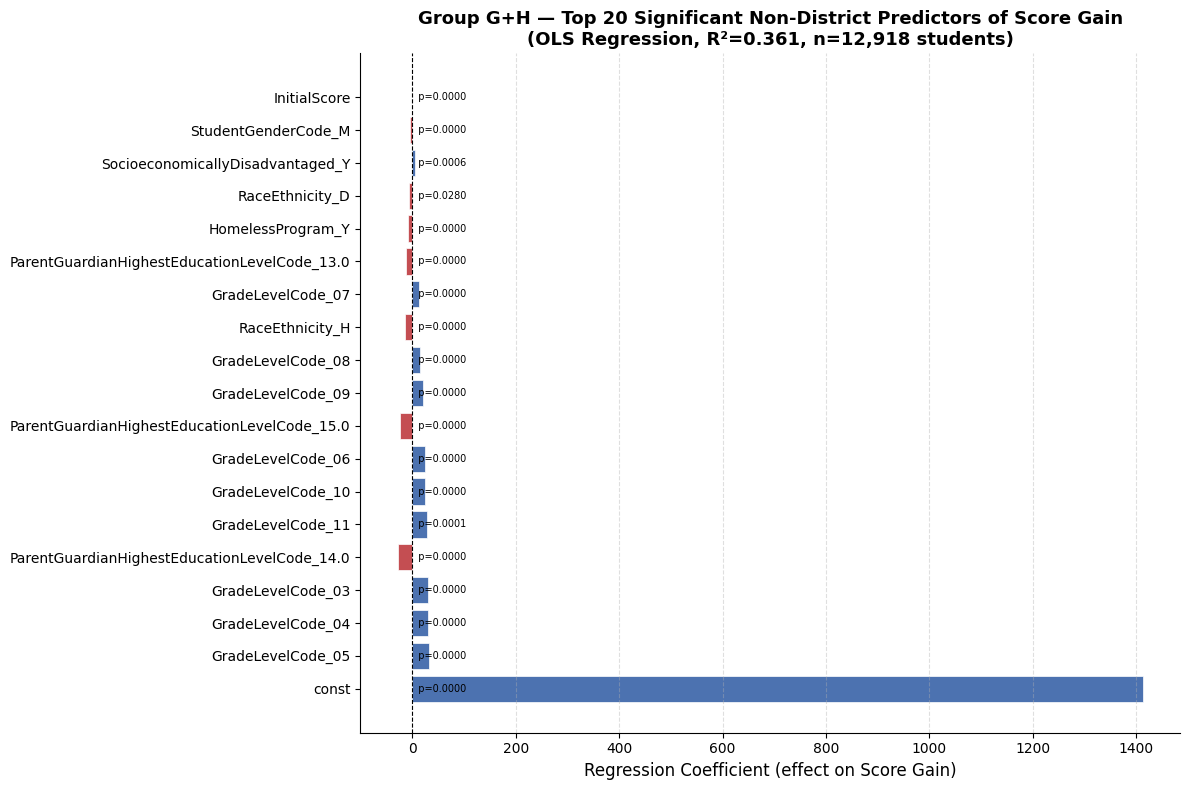

Saved: plots/group_gh_regression_top20.png

Significant district effects: 5


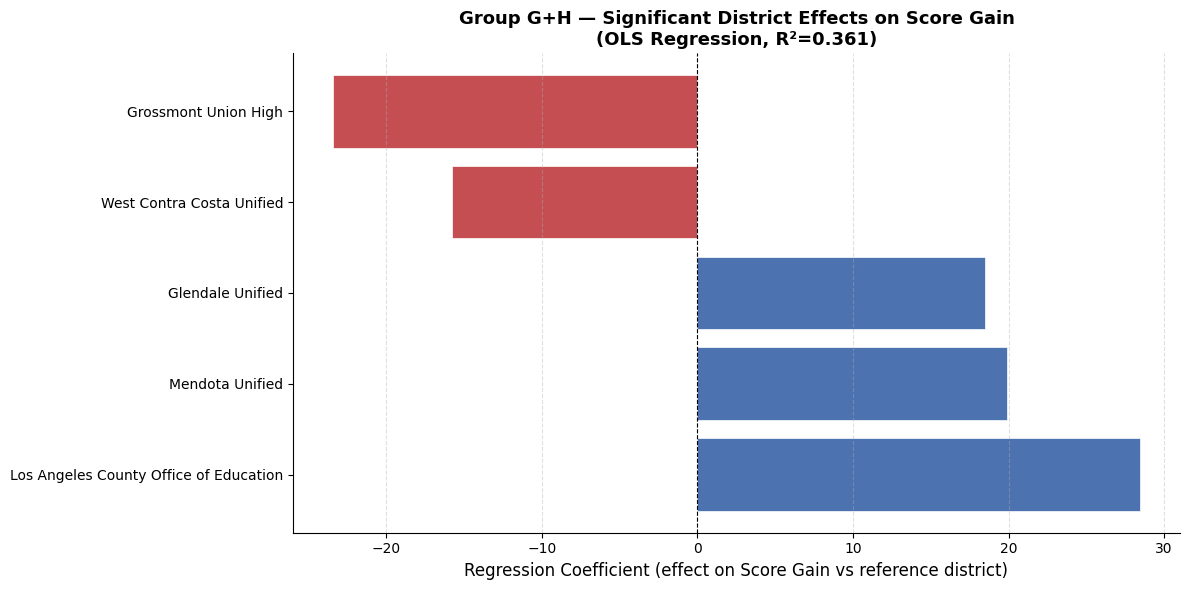

Saved: plots/group_gh_regression_districts.png


In [5]:
# --- Plot 1: Top 20 significant non-district predictors ---
sig_non_district_sorted = sig_non_district.reindex(
    sig_non_district["Coefficient"].abs().sort_values(ascending=False).index
).head(20)

fig, ax = plt.subplots(figsize=(12, 8))
colors = ["#4C72B0" if c >= 0 else "#C44E52" for c in sig_non_district_sorted["Coefficient"]]
ax.barh(sig_non_district_sorted["Variable"], sig_non_district_sorted["Coefficient"],
        color=colors, edgecolor="white", linewidth=0.5)

for i, (_, row) in enumerate(sig_non_district_sorted.iterrows()):
    ax.text(0, i, f"  p={row['P-Value']:.4f}", va="center", fontsize=7)

ax.axvline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_xlabel("Regression Coefficient (effect on Score Gain)", fontsize=12)
ax.set_title("Group G+H — Top 20 Significant Non-District Predictors of Score Gain\n"
             f"(OLS Regression, R²={model.rsquared:.3f}, n={len(y_np):,} students)",
             fontsize=13, fontweight="bold")
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("plots/group_gh_regression_top20.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: plots/group_gh_regression_top20.png")

# --- Plot 2: Significant district effects ---
sig_districts = results[
    results["Significant"] &
    results["Variable"].str.startswith("Districtname_")
].copy()
sig_districts["District"] = sig_districts["Variable"].str.replace("Districtname_", "", regex=False)
sig_districts = sig_districts.reindex(
    sig_districts["Coefficient"].sort_values(ascending=False).index
)

print(f"\nSignificant district effects: {len(sig_districts)}")

if len(sig_districts) > 0:
    fig, ax = plt.subplots(figsize=(12, max(6, len(sig_districts) * 0.35)))
    colors = ["#4C72B0" if c >= 0 else "#C44E52" for c in sig_districts["Coefficient"]]
    ax.barh(sig_districts["District"], sig_districts["Coefficient"],
            color=colors, edgecolor="white", linewidth=0.5)

    ax.axvline(0, color="black", linewidth=0.8, linestyle="--")
    ax.set_xlabel("Regression Coefficient (effect on Score Gain vs reference district)", fontsize=12)
    ax.set_title("Group G+H — Significant District Effects on Score Gain\n"
                 f"(OLS Regression, R²={model.rsquared:.3f})",
                 fontsize=13, fontweight="bold")
    ax.grid(axis="x", linestyle="--", alpha=0.4)
    ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    plt.savefig("plots/group_gh_regression_districts.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved: plots/group_gh_regression_districts.png")

# Group G+H Regression Analysis: Key Findings

## Overview

This regression analyzes what demographic factors predict English language score
gains for foreign-born students (Groups G and H) who had an Initial ELPAC
assessment in 2022, three years of Summative assessments, and enrollment records
across all three years. The outcome variable is the gain in Overall Scale Score
from the Initial assessment to the third Summative test.

---

## Overall Model Strength

The model includes grade level, parent education, race/ethnicity, gender,
socioeconomic status, homeless status, migrant status, district, and other
demographic variables. The overall model is statistically significant, meaning
the demographic variables together are genuinely predictive of how much a student
improves.

---

## Key Findings by Variable

### Starting Score (InitialScore, coefficient = -0.63)

The strongest predictor. Students who start with a lower initial score gain more
points over the three years. For every 10 points higher a student starts, they
gain about 6.3 fewer points — confirming that lower-starting students benefit
most from the program. This is consistent with the earlier Group E+F findings.

---

### Grade Level

Most grade levels show significantly higher gains than Grade 1 (the reference
group). The pattern differs somewhat from the E+F analysis — the strongest gains
now appear in Grades 3–5 and Grades 10–11, while Grades 7–8 show smaller but
still significant advantages.

| Grade | Coefficient | Significant |
|-------|-------------|-------------|
| Kindergarten | -3.2 | No |
| Grade 2 | +2.9 | No |
| Grade 3 | +30.4 | Yes |
| Grade 4 | +30.9 | Yes |
| Grade 5 | +31.7 | Yes |
| Grade 6 | +24.7 | Yes |
| Grade 7 | +13.1 | Yes |
| Grade 8 | +15.3 | Yes |
| Grade 9 | +21.0 | Yes |
| Grade 10 | +25.2 | Yes |
| Grade 11 | +28.6 | Yes |

Grades 3–5 and 10–11 show the strongest advantage. Kindergarten and Grade 2
show no significant difference from Grade 1.

---

### Parent Education Level

A striking finding: students whose parents have a graduate school education
(code 14) show the largest negative effect at -28.8 points — nearly double what
was seen in the E+F group (-14.0 points). Students whose parents declined to
state their education level (code 15) also show a large negative effect (-23.7
points). This pattern is even stronger in the foreign-born population than in
the broader E+F group.

| Parent Education Level | Coefficient | Significant |
|------------------------|-------------|-------------|
| High School Graduate | +0.3 | No |
| Some College | -3.0 | No |
| College Graduate | -12.0 | Yes |
| Graduate School | -28.8 | Yes |
| Declined to State | -23.7 | Yes |

Reference group: parents who did not graduate high school. This pattern likely
reflects that foreign-born families with higher education may have different
engagement patterns with the EL program, or that their children's initial scores
are closer to the upper range even after controlling for the initial score variable.

---

### Race / Ethnicity

Only two race/ethnicity groups show statistically significant differences in this
foreign-born population:

| Race / Ethnicity | Coefficient | Significant |
|------------------|-------------|-------------|
| Hispanic/Latino | -13.7 | Yes |
| Asian | -7.2 | Yes |
| Filipino | -12.5 | No (p=0.076) |
| American Indian/Alaska Native | -25.7 | No (p=0.110) |
| Pacific Islander | -11.7 | No |
| Black/African American | -4.2 | No |
| White | +1.8 | No |
| Two or More Races | -4.3 | No |

Notably, many race/ethnicity effects that were significant in the E+F group
(which included US-born students) are no longer significant here. This suggests
that some of those earlier effects may have been partly driven by country of
birth rather than race/ethnicity alone.

---

### Gender (coefficient = -4.39)

Male students gain about 4.4 fewer points than female students — slightly larger
than the E+F finding of -3.7. This is statistically significant and consistent
across both analyses.

---

### Socioeconomically Disadvantaged (coefficient = +4.68) ⚠️ Notable Change

This result is strikingly different from the E+F analysis, where SED status was
associated with *lower* gains (-1.77). In the foreign-born population, being
socioeconomically disadvantaged is associated with *higher* gains (+4.68 points).
This may reflect that lower-income foreign-born families rely more heavily on
school-based English instruction, making the program more impactful for this
subgroup.

---

### Homeless Students (coefficient = -7.76)

Homeless students gain about 7.8 fewer points than non-homeless students — a
larger gap than in the E+F group (-5.3 points). Housing instability appears to
be an even greater barrier to language learning progress for foreign-born students.

---

### Group G vs Group H (coefficient = -4.78, NOT significant)

Unlike the E+F analysis where Group F (Intermediate) showed significantly lower
gains than Group E (Novice), here the difference between Groups G and H is not
statistically significant (p=0.17). For foreign-born students, starting
proficiency level (Novice vs Intermediate) does not independently predict how
much they gain over three years.

---

### Variables with No Significant Effect

The following showed no meaningful independent effect on score gains:

- Spanish speaker (Primary Language)
- Migrant status
- Unaccompanied Youth
- Foster care
- Most race/ethnicity categories (see table above)
- Kindergarten and Grade 2

---

## District Effects

Five districts showed statistically significant effects on student score gains,
after controlling for all other demographic variables. These effects represent
how much better or worse students in each district perform compared to the
reference district, holding everything else equal.

### Positive District Effects (students gain more)

| District | Coefficient | Significant |
|----------|-------------|-------------|
| Los Angeles County Office of Education | +28.4 | Yes |
| Mendota Unified | +19.9 | Yes |
| Glendale Unified | +18.5 | Yes |

**Los Angeles County Office of Education** shows the strongest positive effect
(+28.4 points), suggesting that students in this district's programs gain
substantially more than the reference district after accounting for demographics.
**Mendota Unified** (+19.9) and **Glendale Unified** (+18.5) also show strong
positive effects, indicating these districts may be implementing particularly
effective English learner support.

### Negative District Effects (students gain less)

| District | Coefficient | Significant |
|----------|-------------|-------------|
| Grossmont Union High | -23.4 | Yes |
| West Contra Costa Unified | -15.8 | Yes |

**Grossmont Union High** shows the largest negative district effect (-23.4
points), meaning students there gain significantly less than the reference
district even after controlling for demographics. **West Contra Costa Unified**
(-15.8) also shows a significant negative effect.

### Near-Significant Districts (worth monitoring)

These districts did not quite reach the p<0.05 threshold but show notable trends:

| District | Coefficient | P-Value |
|----------|-------------|---------|
| Los Angeles Unified | +12.5 | 0.064 |
| Twin Rivers Unified | -13.5 | 0.059 |
| San Francisco Unified | -13.1 | 0.073 |

---

## Comparison with Group E+F Findings

| Variable | E+F Result | G+H Result | Change |
|----------|------------|------------|--------|
| Initial Score | -0.73 | -0.63 | Similar |
| Grade 3-5 | ~+33 pts | ~+31 pts | Similar |
| Parent Ed (Grad School) | -14.0 | -28.8 | Much stronger |
| Hispanic/Latino | -14.7 | -13.7 | Similar |
| Gender (Male) | -3.7 | -4.4 | Similar |
| SED Status | -1.8 | +4.7 | Reversed |
| Homeless | -5.3 | -7.8 | Stronger |
| Group F vs E / H vs G | -5.9 (sig) | -4.8 (not sig) | No longer significant |

---

## Bottom Line

For foreign-born English learners with three years of Summative data, the most
important predictors of score gain are starting score, grade level (Grades 3–5
and 9–11 perform best), parent education level (higher education associated with
lower gains), and — notably — which district a student attends. The district
effects are a new and important finding: after controlling for all student
demographics, some districts are producing significantly better outcomes than
others, which points to district-level program implementation as a meaningful
driver of student progress.